# 03 — Treino e competição dos modelos

**Frente:** Dev 3 · **Critérios:** 5 (dois modelos competindo nas mesmas condições) e 8 (rastreio no MLflow)

Este notebook roda a cada ciclo, logo depois do `02_votacao_features.ipynb`:

1. **Features do ciclo**: lê `artifacts/<cycle_id>/features_eleitas.json` do Dev 2 e confere que a votação foi feita sobre o `data_version` atual das partições.
2. **Dois candidatos como `Pipeline`** (`src/modelagem.py`): pré-processamento do Dev 1 → seleção das features eleitas → estimador. O modelo serializado já carrega o pré-processamento e a lista de features.
   - **Modelo A:** `LogisticRegression(class_weight='balanced')`
   - **Modelo B:** `XGBClassifier(scale_pos_weight = legítimas/fraudes no treino)`
3. **Mesmo treino, mesmas features, mesma validação**, seeds fixas: precision, recall, F1 (classe fraude) e matriz de confusão.
4. **Um run MLflow por modelo**, com tags `cycle_id`, `data_version` e `algoritmo`, hiperparâmetros, métricas, features e o modelo (`mlflow.sklearn.log_model`).

O **teste não é usado aqui**: a escolha do vencedor e a promoção (notebook 04) olham só para a validação.

In [1]:
import os, sys, json
from pathlib import Path

# funciona tanto rodando de notebooks/ (nbconvert) quanto da raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.ingestao import carregar_config
from src.preprocessamento import carregar_particoes, ALVO
from src.modelagem import (resolver_ciclo, treinar_candidatos, tabela_comparativa,
                           registrar_candidato, gravar_competicao, carregar_competicao,
                           carregar_modelo, avaliar, limiar, METRICAS)

cfg = carregar_config()

# cycle_id: o do workflow (CYCLE_ID) ou, localmente, o da votação mais recente do notebook 02
ciclo = resolver_ciclo(cfg=cfg)
CYCLE_ID, DATA_VERSION = ciclo["cycle_id"], ciclo["data_version"]
FEATURES, ELEITAS = ciclo["features"], ciclo["eleitas"]
print("cycle_id:            ", CYCLE_ID)
print("data_version:        ", DATA_VERSION)
print("features candidatas: ", len(FEATURES))
print(f"features eleitas ({len(ELEITAS)}):", ELEITAS)
print("run da votação:      ", ciclo["votacao_run_id"])
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)

cycle_id:             20261127-2025-r9
data_version:         v1-65ada979
features candidatas:  38
features eleitas (6): ['total_transactions_including_tnx_to_create_contract', 'avg_val_received', 'total_ether_received', 'erc20_uniq_rec_token_name', 'total_erc20_tnxs', 'unique_received_from_addresses']
run da votação:       a022517e276940098bfd877659520daa


## 1. Partições do ciclo

Treino para ajustar tudo (pré-processamento, seleção e estimador); validação para comparar os modelos. O teste fica reservado para o número final do relatório e para o notebook 05.

In [2]:
treino, validacao, teste = carregar_particoes(cfg)
resumo = pd.DataFrame({
    nome: {"linhas": len(df), "fraudes": int(df[ALVO].sum()), "taxa_fraude": round(df[ALVO].mean(), 4)}
    for nome, df in [("treino", treino), ("validacao", validacao)]
}).T
print("teste reservado (não usado neste notebook):", len(teste), "linhas")
resumo

teste reservado (não usado neste notebook): 1367 linhas


,linhas,fraudes,taxa_fraude
treino,4205.0,946.0,0.2250
validacao,1306.0,271.0,0.2075


## 2. Candidatos

Os dois candidatos recebem **exatamente** a mesma lista de features eleitas e o mesmo treino. Os hiperparâmetros são fixos e estão no `config.yaml` (`modelos.hiperparametros`): a competição é entre algoritmos, não entre buscas de hiperparâmetro, e não há ajuste olhando a validação.

O desbalanceamento (≈ 22% de fraude) é tratado de forma equivalente nos dois: `class_weight='balanced'` na Regressão Logística e `scale_pos_weight = legítimas / fraudes` (calculado no treino) no XGBoost. A classificação usa o limiar 0,5 de probabilidade.

In [3]:
candidatos = treinar_candidatos(treino, validacao, FEATURES, ELEITAS, cfg)
for nome, c in candidatos.items():
    print(f"Modelo {nome} — {c['algoritmo']}")
    print("   ", {k: v for k, v in c["params"].items()})
print()
print(candidatos["B"]["pipeline"])

# garantia do critério 5: mesmas features nos dois estimadores
for c in candidatos.values():
    assert list(c["pipeline"].named_steps["modelo"].feature_names_in_) == ELEITAS

Modelo A — logistic_regression
    {'C': 1.0, 'max_iter': 2000, 'class_weight': 'balanced', 'random_state': 42}
Modelo B — xgboost
    {'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.9, 'min_child_weight': 1, 'scale_pos_weight': 3.445032, 'eval_metric': 'logloss', 'tree_method': 'hist', 'random_state': 42, 'n_jobs': 1}

Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<function log_com_sinal at 0x7933c1baf560>)),
                                                                  ('imputer',
                                                                   SimpleImputer(strategy='median')),
                                 

## 3. Avaliação na validação

Métrica principal: **F1 da classe fraude** (fixada no `config.yaml` antes do ciclo 1). Precision e recall explicam de onde vem o F1; ROC AUC e average precision medem a ordenação das probabilidades, independentemente do limiar.

In [4]:
comparacao = tabela_comparativa(candidatos)
comparacao

,algoritmo,f1,precision,recall,roc_auc,average_precision,tp,fp,fn,tn
modelo,,,,,,,,,,
A,logistic_regression,0.7036,0.5821,0.8893,0.9382,0.7927,241,173,30,862
B,xgboost,0.9159,0.8889,0.9446,0.9938,0.9791,256,32,15,1003


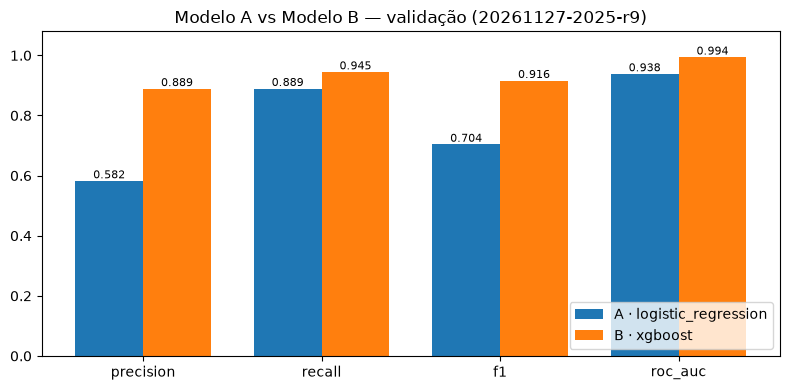

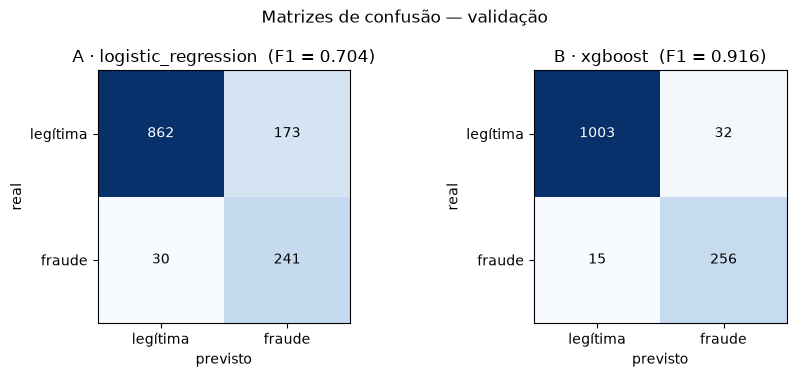

In [5]:
nomes = {n: f"{n} · {c['algoritmo']}" for n, c in candidatos.items()}
metricas_plot = ["precision", "recall", "f1", "roc_auc"]
cores = {"A": "tab:blue", "B": "tab:orange"}

fig_comp, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(metricas_plot)); w = 0.38
for i, (n, c) in enumerate(candidatos.items()):
    vals = [c["metricas_validacao"][m] for m in metricas_plot]
    barras = ax.bar(x + (i - 0.5) * w, vals, w, label=nomes[n], color=cores[n])
    ax.bar_label(barras, fmt="%.3f", fontsize=8)
ax.set_xticks(x, metricas_plot); ax.set_ylim(0, 1.08); ax.legend(loc="lower right")
ax.set_title(f"Modelo A vs Modelo B — validação ({CYCLE_ID})")
plt.tight_layout(); plt.show()

fig_cm, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (n, c) in zip(axes, candidatos.items()):
    m = c["metricas_validacao"]
    mat = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    ax.imshow(mat, cmap="Blues")
    for (i, j), v in np.ndenumerate(mat):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > mat.max() / 2 else "black")
    ax.set_xticks([0, 1], ["legítima", "fraude"]); ax.set_yticks([0, 1], ["legítima", "fraude"])
    ax.set_xlabel("previsto"); ax.set_ylabel("real"); ax.set_title(f"{nomes[n]}  (F1 = {m['f1']:.3f})")
fig_cm.suptitle("Matrizes de confusão — validação")
plt.tight_layout(); plt.show()

## 4. Registro no MLflow e artefato do ciclo

Um run por modelo (etapa `treino_competicao`), no mesmo experimento e `mlflow.db` dos notebooks 01 e 02:

| Onde | O quê |
|---|---|
| tags | `cycle_id`, `data_version`, `algoritmo`, `modelo` (A/B), `etapa`, `votacao_run_id` |
| params | `hp.*` (hiperparâmetros), `seed`, `limiar_classificacao`, `n_features`, `features` |
| metrics | `val_f1`, `val_precision`, `val_recall`, `val_roc_auc`, `val_average_precision`, `val_tp/fp/fn/tn` |
| artifacts | `modelo/` (pipeline completo), `features.json`, `matriz_confusao_validacao.json`, figuras |

`artifacts/<cycle_id>/competicao.json` liga os dois runs ao ciclo: é o que o notebook 04 lê para decidir a promoção e o que o painel do Dev 5 usa na tela de competição.

In [6]:
for nome, c in candidatos.items():
    registrar_candidato(c, ciclo, validacao, cfg, figuras={
        "figuras/comparacao_validacao.png": fig_comp,
        "figuras/matrizes_confusao_validacao.png": fig_cm,
    })
    print(f"Modelo {nome} ({c['algoritmo']:20s}) run_id = {c['run_id']}")

arq = gravar_competicao(candidatos, ciclo, cfg)
print("artefato:", arq.relative_to(RAIZ).as_posix())

2026/11/27 20:25:44 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/27 20:25:47 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Modelo A (logistic_regression ) run_id = 5b12e1852f5b4cd09843a9313a3b78c5


Modelo B (xgboost             ) run_id = f9a1c13bf0504f0ba4edc63ecd5ded04
artefato: artifacts/20261127-2025-r9/competicao.json


**Conferência:** o modelo recarregado do MLflow (como fará o notebook 04 e o 05) reproduz exatamente as métricas de validação.

In [7]:
comp = carregar_competicao(CYCLE_ID, cfg)
for nome, c in comp["candidatos"].items():
    recarregado = carregar_modelo(c["run_id"], cfg)
    f1 = avaliar(recarregado, validacao, cfg)["f1"]
    assert abs(f1 - c["metricas_validacao"]["f1"]) < 1e-12
    print(f"{nome}: {c['model_uri']}  F1_val recarregado = {f1:.4f}  ✔")
assert comp["features"] == ELEITAS and comp["data_version"] == DATA_VERSION

A: runs:/5b12e1852f5b4cd09843a9313a3b78c5/modelo  F1_val recarregado = 0.7036  ✔
B: runs:/f9a1c13bf0504f0ba4edc63ecd5ded04/modelo  F1_val recarregado = 0.9159  ✔


### Entregas para as outras frentes
- **Notebook 04 (promoção):** `carregar_competicao(CYCLE_ID)` → `run_id`, `algoritmo` e métricas de validação de A e B.
- **Dev 4 (workflow):** este notebook lê `CYCLE_ID` do ambiente; os modelos ficam em `mlartifacts/` (via MLflow) e `artifacts/<cycle_id>/competicao.json` deve ser persistido junto.
- **Dev 5 (painel):** `artifacts/<cycle_id>/competicao.json` (métricas de A e B) e `comparacao_modelos.csv`; as métricas do vigente vêm do `decisao.json` do notebook 04.
- **Relatório:** seção "Comparação dos modelos" (`docs/competicao_promocao.md`).